# Deep Learning · PR 6
## Opening the Transformer: Attention, Encoder, Decoder and Inference with Pretrained Models

- No model is trained here. Small pretrained Hugging Face models are used and inspected.
- Models used: `distilbert-base-uncased-finetuned-sst-2-english` (encoder), `gpt2` (decoder), `t5-small` (encoder-decoder).

In [1]:
# pip install transformers torch datasets matplotlib seaborn numpy pandas

In [2]:
import numpy as np
import torch

np.random.seed(42)
torch.manual_seed(42)

In [3]:
import os

os.makedirs("plots", exist_ok=True)

## Task 1: Introduction, History, Pipelines & Tokenizer
**Objective:** Run a first pipeline, learn the background of Transformers, and look at the tokenizer and the model structure.

**Expected output:** Sentiment results, history and impact notes, token ids, a padded batch, and a table of model facts.

### 1.1 First pipeline

In [4]:
from transformers import pipeline

C:\Users\aisam\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
model_name = "distilbert-base-uncased-finetuned-sst-2-english"
clf = pipeline("sentiment-analysis", model=model_name)

C:\Users\aisam\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\aisam\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\aisam\AppData\Local\Programs\Python\Python312\Lib\site-pac

In [6]:
sentences = [
    "I loved this movie, the acting was wonderful.",
    "The food was cold and the service was terrible.",
    "The story was not bad at all.",
    "I did not enjoy the ending of the film.",
    "The phone is fine, but the battery could be much better.",
]

In [7]:
results = clf(sentences)

In [8]:
for sentence, result in zip(sentences, results):
    print(result["label"], round(result["score"], 4), "|", sentence)

POSITIVE 0.9999 | I loved this movie, the acting was wonderful.
NEGATIVE 0.9997 | The food was cold and the service was terrible.
POSITIVE 0.9985 | The story was not bad at all.
NEGATIVE 0.999 | I did not enjoy the ending of the film.
NEGATIVE 0.9754 | The phone is fine, but the battery could be much better.


**Interpretation**
- One pipeline call hides three steps: tokenisation, model forward pass and post-processing (softmax to label and score).
- The sentences with negation ("not bad", "did not enjoy") are the tricky ones. Check if the label matches the real meaning.
- The score is the confidence of the model, not a guarantee that the label is correct.

### 1.2 Introduction and history
| Year | Model / Paper | Why it mattered |
|---|---|---|
| 2014-15 | Seq2seq with attention (Bahdanau, Luong) | The decoder could look at all encoder states instead of one fixed vector |
| 2017 | "Attention Is All You Need" (Vaswani et al.) | Removed RNNs completely, only attention, training in parallel |
| 2018 | BERT and GPT | Pretrain once on large text, then reuse for many tasks |
| 2019 | GPT-2, T5, DistilBERT | Better text generation, text-to-text idea, smaller and faster BERT |
| 2020 and later | GPT-3 and other large language models, Vision Transformer | Scaling up, and Transformers moved to images and chat assistants |

**What problem of RNN / LSTM did the Transformer solve?**
- RNNs read tokens one by one, so training cannot run in parallel and is slow.
- Information from early tokens fades in long sequences (short memory).
- Attention lets every token look at every other token directly, and all tokens are processed together.

### 1.3 Impact and disadvantages
**Impact**
- Machine translation and search ranking
- Chat assistants and code completion
- Image models (Vision Transformer) and protein structure prediction

**Disadvantages**
- Attention cost grows with the square of the sequence length
- Fixed context window
- Large compute and memory needs, and huge data needs
- Hallucination in generative models
- Opaque behaviour (hard to explain)

Two of these (cost and hallucination) are measured in Task 6.

### 1.4 Tokenizer in action

In [9]:
from transformers import AutoTokenizer

In [10]:
tok = AutoTokenizer.from_pretrained(model_name)

In [11]:
text = "Transformers are surprisingly easy to understand."
tokens = tok.tokenize(text)
print(tokens)

['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']


In [12]:
encoded = tok(text)
print(encoded["input_ids"])
print(encoded["attention_mask"])

[101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]
[1, 1, 1, 1, 1, 1, 1, 1, 1]


In [13]:
print(tok.convert_ids_to_tokens(encoded["input_ids"]))

['[CLS]', 'transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.', '[SEP]']


In [14]:
rare_word = "electroencephalography"
print(tok.tokenize(rare_word))

['electro', '##ence', '##pha', '##log', '##raphy']


**Interpretation**
- `[CLS]` is added at the start and `[SEP]` at the end of every sentence. `[CLS]` is used as a summary position for classification.
- A rare or long word is split into sub-word pieces (pieces after the first start with `##`).
- Sub-words keep the vocabulary small and still allow the model to read any new word.

### 1.5 Batching and padding

In [15]:
two_sentences = ["I like it.", "This movie was much longer than I expected but still enjoyable."]
batch = tok(two_sentences, padding=True, return_tensors="pt")

In [16]:
for i in range(len(two_sentences)):
    print("input_ids     :", batch["input_ids"][i].tolist())
    print("attention_mask:", batch["attention_mask"][i].tolist())
    print()

input_ids     : [101, 1045, 2066, 2009, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0]
attention_mask: [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]

input_ids     : [101, 2023, 3185, 2001, 2172, 2936, 2084, 1045, 3517, 2021, 2145, 22249, 1012, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]



**Interpretation**
- The shorter sentence is filled with padding id 0 so both sentences have the same length.
- `attention_mask` is 1 for real tokens and 0 for padding, so the model can ignore the padding. The effect is checked in Task 4.

### 1.6 Model anatomy at a glance

In [17]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 588.92it/s]


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [18]:
print(model.config)

DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForSequenceClassification"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "finetuning_task": "sst-2",
  "hidden_dim": 3072,
  "id2label": {
    "0": "NEGATIVE",
    "1": "POSITIVE"
  },
  "initializer_range": 0.02,
  "label2id": {
    "NEGATIVE": 0,
    "POSITIVE": 1
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "output_past": true,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.20.0",
  "vocab_size": 30522
}



In [19]:
total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", total_params)

Total parameters: 66955010


In [20]:
count = 0
for name, p in model.named_parameters():
    print(name, tuple(p.shape))
    count = count + 1
    if count == 15:
        break

distilbert.embeddings.word_embeddings.weight (30522, 768)
distilbert.embeddings.position_embeddings.weight (512, 768)
distilbert.embeddings.LayerNorm.weight (768,)
distilbert.embeddings.LayerNorm.bias (768,)
distilbert.transformer.layer.0.attention.q_lin.weight (768, 768)
distilbert.transformer.layer.0.attention.q_lin.bias (768,)
distilbert.transformer.layer.0.attention.k_lin.weight (768, 768)
distilbert.transformer.layer.0.attention.k_lin.bias (768,)
distilbert.transformer.layer.0.attention.v_lin.weight (768, 768)
distilbert.transformer.layer.0.attention.v_lin.bias (768,)
distilbert.transformer.layer.0.attention.out_lin.weight (768, 768)
distilbert.transformer.layer.0.attention.out_lin.bias (768,)
distilbert.transformer.layer.0.sa_layer_norm.weight (768,)
distilbert.transformer.layer.0.sa_layer_norm.bias (768,)
distilbert.transformer.layer.0.ffn.lin1.weight (3072, 768)


In [21]:
import pandas as pd

config = model.config
facts = pd.DataFrame({
    "Item": ["Layers", "Attention heads", "Hidden size", "Vocabulary size", "Max position embeddings", "Total parameters"],
    "Value": [config.num_hidden_layers, config.num_attention_heads, config.hidden_size,
              config.vocab_size, config.max_position_embeddings, total_params],
})
facts

,Item,Value
0,Layers,6
1,Attention heads,12
2,Hidden size,768
3,Vocabulary size,30522
4,Max position embeddings,512
5,Total parameters,66955010


**Interpretation**
- Layers, heads and hidden size are explained in Tasks 2 to 4. Hidden size divided by heads gives the size of one head.
- Max position embeddings is the longest input the model can accept.

### Final interpretation: Task 1
- A pipeline is easy to use, but inside it there are a tokenizer and a model with many parameters.
- Tokens, special tokens, padding and the attention mask are the input format every Transformer expects.

## Task 2: Self-Attention & Scaled Dot-Product Attention
**Objective:** Build self-attention by hand in NumPy and check it against a real model.

**Expected output:** Attention heatmap, scaling experiment, Luong attention, order-blindness proof, and a match with DistilBERT.

### 2.1 Self-attention idea
- Every token is turned into three vectors: a Query (what am I looking for), a Key (what do I offer) and a Value (what do I pass on).
- The new vector of a token is a weighted average of all Value vectors. The weights come from how well its Query matches every Key.
- The whole sequence is processed in parallel, unlike an RNN.

### 2.2 Scaled dot-product attention from scratch

In [22]:
rng = np.random.default_rng(7)
n_tokens = 4
d_model = 8
X = rng.standard_normal((n_tokens, d_model))
print("X:", X.shape)

X: (4, 8)


In [23]:
Wq = rng.standard_normal((d_model, d_model))
Wk = rng.standard_normal((d_model, d_model))
Wv = rng.standard_normal((d_model, d_model))

In [24]:
Q = X @ Wq
K = X @ Wk
V = X @ Wv
print("Q:", Q.shape, "K:", K.shape, "V:", V.shape)

Q: (4, 8) K: (4, 8) V: (4, 8)


In [25]:
d_k = K.shape[1]
scores = Q @ K.T / np.sqrt(d_k)
print("scores:", scores.shape)

scores: (4, 4)


In [26]:
def softmax(x):
    x = x - np.max(x, axis=-1, keepdims=True)
    e = np.exp(x)
    return e / np.sum(e, axis=-1, keepdims=True)

In [27]:
weights = softmax(scores)
output = weights @ V
print("weights:", weights.shape)
print("output:", output.shape)

weights: (4, 4)
output: (4, 8)


In [28]:
print("Row sums:", weights.sum(axis=1))
print("All rows sum to 1:", np.allclose(weights.sum(axis=1), 1))

Row sums: [1. 1. 1. 1.]
All rows sum to 1: True


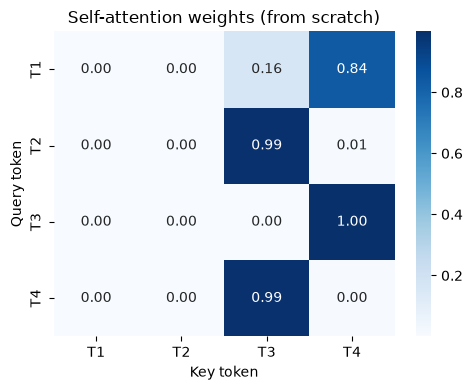

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = []
for i in range(n_tokens):
    labels.append("T" + str(i + 1))

plt.figure(figsize=(5, 4))
sns.heatmap(weights, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Self-attention weights (from scratch)")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.tight_layout()
plt.savefig("plots/attention_scratch.png", dpi=150)
plt.show()

**Interpretation**
- Each row is one query token. The numbers in a row are how much it attends to every token, and the row sums to 1.
- A darker cell means a stronger match between that Query and that Key.

In [30]:
def self_attention(X, Wq, Wk, Wv, mask=None):
    Q = X @ Wq
    K = X @ Wk
    V = X @ Wv
    scores = Q @ K.T / np.sqrt(K.shape[1])
    if mask is not None:
        scores = scores + mask
    weights = softmax(scores)
    return weights, weights @ V

### 2.3 Why divide by sqrt(d_k)?

In [31]:
def softmax_stats(d_k, scaled):
    Qr = rng.standard_normal((50, d_k))
    Kr = rng.standard_normal((50, d_k))
    s = Qr @ Kr.T
    if scaled:
        s = s / np.sqrt(d_k)
    w = softmax(s)
    max_prob = w.max(axis=1).mean()
    entropy = (-(w * np.log(w + 1e-12)).sum(axis=1)).mean()
    return max_prob, entropy

In [32]:
rows = []
for d in [4, 256]:
    for scaled in [False, True]:
        max_prob, entropy = softmax_stats(d, scaled)
        rows.append({"d_k": d, "scaled": scaled, "avg max probability": round(max_prob, 3), "avg entropy": round(entropy, 3)})

scale_table = pd.DataFrame(rows)
scale_table

,d_k,scaled,avg max probability,avg entropy
0,4,False,0.259,2.824
1,4,True,0.118,3.511
2,256,False,0.916,0.255
3,256,True,0.121,3.463


**Interpretation**
- Dot products grow bigger when d_k is bigger. Without scaling, softmax becomes saturated: one weight is close to 1 and the others are close to 0 (high max probability, low entropy).
- In the saturated region the gradients almost vanish, so learning becomes hard.
- Dividing by sqrt(d_k) keeps the variance of the scores near 1, so the weights stay spread out for both d_k values.

### 2.4 Self-attention vs Luong attention

In [33]:
encoder_states = rng.standard_normal((5, 8))
decoder_state = rng.standard_normal(8)

In [34]:
luong_scores = encoder_states @ decoder_state
luong_weights = softmax(luong_scores)
context = luong_weights @ encoder_states
print("Weights:", np.round(luong_weights, 3))
print("Sum:", luong_weights.sum())
print("Context shape:", context.shape)

Weights: [0.016 0.018 0.388 0.027 0.551]
Sum: 1.0
Context shape: (8,)


| Point | Luong attention | Self-attention |
|---|---|---|
| Where Q, K, V come from | Query = decoder state, Keys/Values = encoder states | All three come from the same sequence |
| What is attended over | Decoder state looks at encoder states | Every token looks at every token |
| Needs an RNN | Yes, built on RNN states | No |
| Parallelism | Limited, RNN steps are sequential | Full parallel over all tokens |
| Position in architecture | Between encoder and decoder | Inside every encoder / decoder block |

**Interpretation**
- Luong attention gives one context vector for one decoder step. Self-attention gives a new vector for every token.

### 2.5 Attention is order-blind

In [35]:
perm = rng.permutation(n_tokens)
print("Permutation:", perm)
X_shuffled = X[perm]

Permutation: [2 1 3 0]


In [36]:
w_original, out_original = self_attention(X, Wq, Wk, Wv)
w_shuffled, out_shuffled = self_attention(X_shuffled, Wq, Wk, Wv)

In [37]:
print("Shuffled output = shuffled original output:", np.allclose(out_original[perm], out_shuffled))

Shuffled output = shuffled original output: True


**Interpretation**
- Shuffling the input only shuffles the output rows in the same way. Attention does not know the position of a token.
- This is why Task 3 adds positional encoding.

### 2.6 Verify against a real model

In [38]:
from transformers import AutoModel

base = AutoModel.from_pretrained(model_name, attn_implementation="eager")
base.eval()

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 506.18it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [39]:
print(base.transformer.layer[0].attention)

DistilBertSelfAttention(
  (q_lin): Linear(in_features=768, out_features=768, bias=True)
  (k_lin): Linear(in_features=768, out_features=768, bias=True)
  (v_lin): Linear(in_features=768, out_features=768, bias=True)
  (out_lin): Linear(in_features=768, out_features=768, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)


In [40]:
sentence = "The animal did not cross the street because it was too tired."
inputs = tok(sentence, return_tensors="pt")

In [41]:
with torch.no_grad():
    out = base(**inputs, output_hidden_states=True, output_attentions=True)

In [42]:
layer0 = base.transformer.layer[0].attention
x0 = out.hidden_states[0]

with torch.no_grad():
    q = layer0.q_lin(x0)
    k = layer0.k_lin(x0)
print("q:", q.shape)

q: torch.Size([1, 15, 768])


In [43]:
n_heads = base.config.num_attention_heads
head_dim = q.shape[-1] // n_heads
print("Heads:", n_heads, "Head size:", head_dim)

q_heads = q.view(1, -1, n_heads, head_dim).transpose(1, 2)
k_heads = k.view(1, -1, n_heads, head_dim).transpose(1, 2)

Heads: 12 Head size: 64


In [44]:
q_h0 = q_heads[0, 0].numpy()
k_h0 = k_heads[0, 0].numpy()

my_attention = softmax(q_h0 @ k_h0.T / np.sqrt(head_dim))
real_attention = out.attentions[0][0, 0].numpy()

In [45]:
print("Match with real model:", np.allclose(my_attention, real_attention, atol=1e-4))
print("Max absolute difference:", np.abs(my_attention - real_attention).max())

Match with real model: True
Max absolute difference: 4.1218595786540746e-08


**Interpretation**
- A match means the real model uses the same equation: softmax(Q K^T / sqrt(d)) with the learned q_lin and k_lin layers.
- There is no padding in a single sentence, so no mask was needed.

### Final interpretation: Task 2
- Self-attention is just three matrix multiplications, a scaled dot product and a softmax.
- Scaling by sqrt(d_k) keeps the softmax healthy, and the hand-made version matches DistilBERT.
- Attention alone cannot see the order of tokens.

## Task 3: Multi-Head Attention, Positional Encoding & Layer Normalization
**Objective:** Look at real attention heads, build positional encoding and layer normalization.

**Expected output:** Head plots, entropy bars, position heatmaps and a LayerNorm check.

### 3.1 Multi-head attention
- One attention pattern is not enough, because a token may need to look at different things at the same time (previous word, subject, punctuation).
- With h heads, d_model is split into h smaller parts (for DistilBERT 768 = 12 x 64). Each head has its own Q, K, V projections and its own pattern.
- The heads are joined (concatenated) and mixed by an output projection. The total computation stays about the same as one big head.

### 3.2 Extract and plot real attention heads

In [46]:
tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])
attentions = out.attentions

for i in range(len(attentions)):
    print("Layer", i, attentions[i].shape)

Layer 0 torch.Size([1, 12, 15, 15])
Layer 1 torch.Size([1, 12, 15, 15])
Layer 2 torch.Size([1, 12, 15, 15])
Layer 3 torch.Size([1, 12, 15, 15])
Layer 4 torch.Size([1, 12, 15, 15])
Layer 5 torch.Size([1, 12, 15, 15])


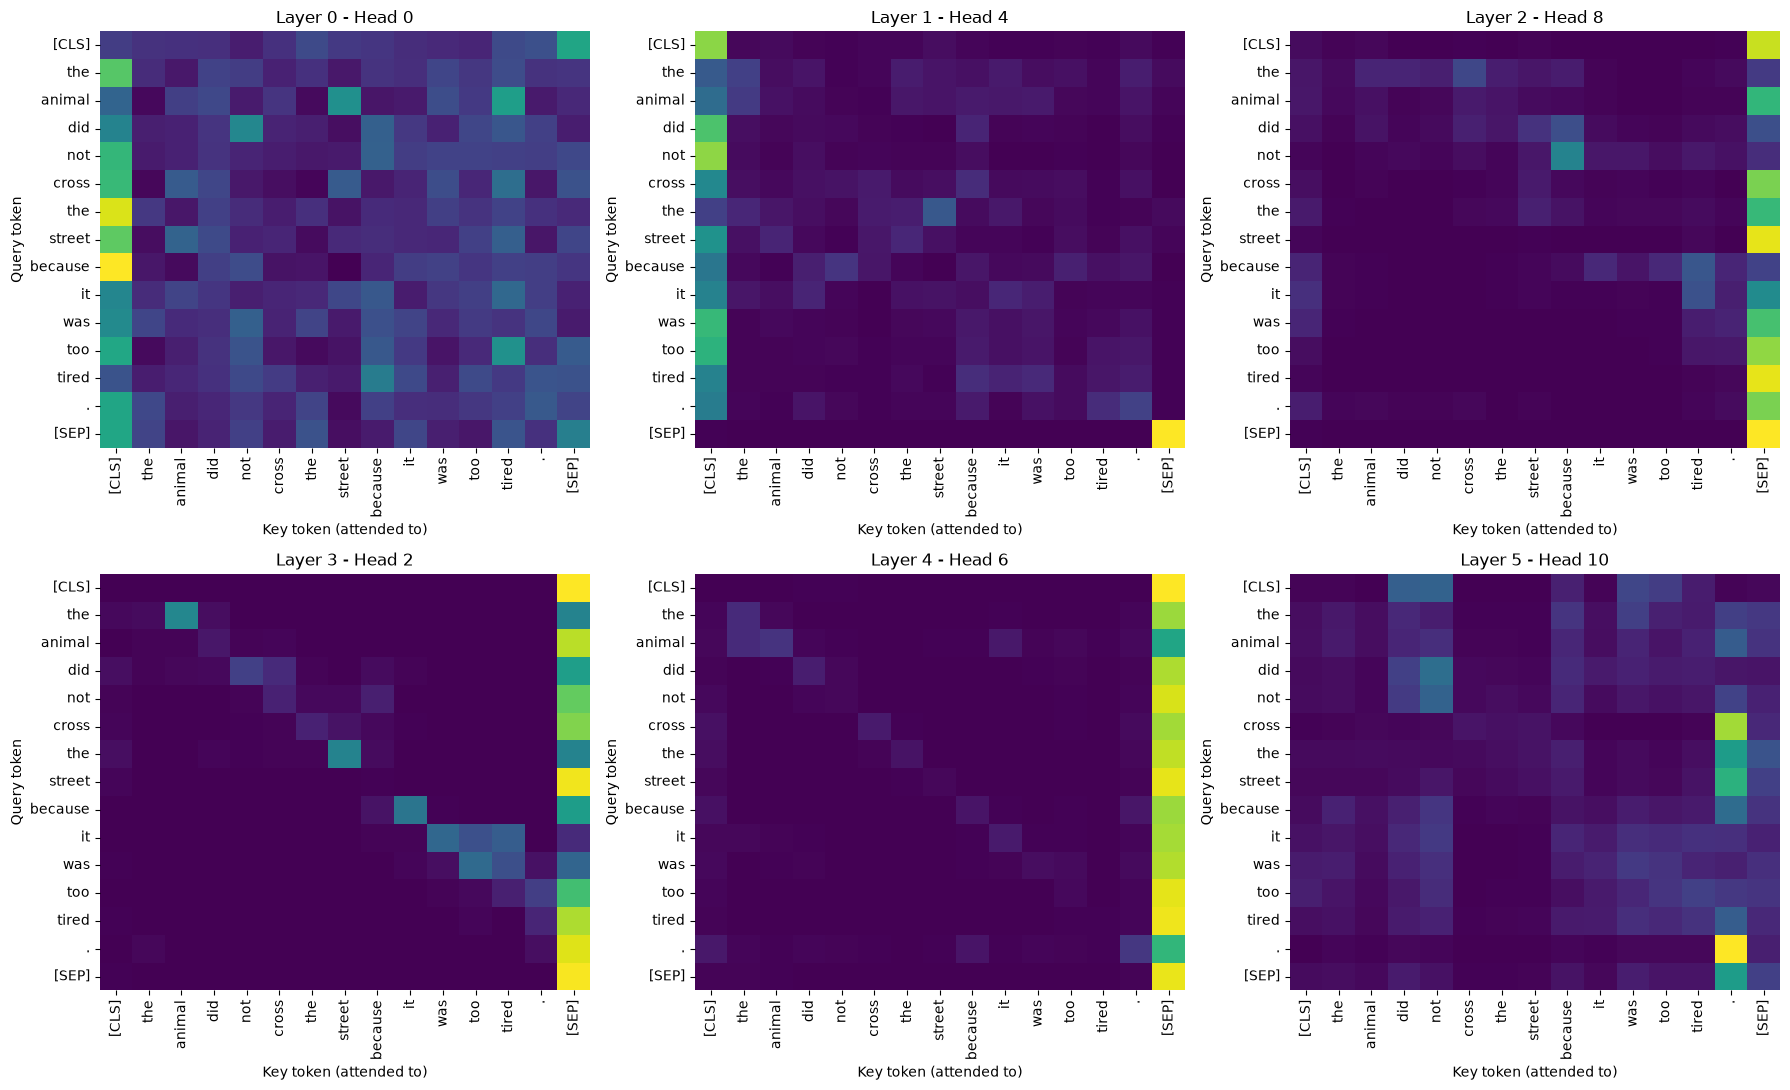

In [47]:
head_list = [(0, 0), (1, 4), (2, 8), (3, 2), (4, 6), (5, 10)]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()
for i in range(len(head_list)):
    layer, head = head_list[i]
    att = attentions[layer][0, head].numpy()
    sns.heatmap(att, xticklabels=tokens, yticklabels=tokens, cmap="viridis", cbar=False, ax=axes[i])
    axes[i].set_title("Layer " + str(layer) + " - Head " + str(head))
    axes[i].set_xlabel("Key token (attended to)")
    axes[i].set_ylabel("Query token")
plt.tight_layout()
plt.savefig("plots/attention_heads.png", dpi=150)
plt.show()

In [48]:
it_pos = tokens.index("it")
rows = []
for layer, head in head_list:
    att = attentions[layer][0, head].numpy()
    prev_values = []
    for i in range(1, len(tokens)):
        prev_values.append(att[i, i - 1])
    rows.append({
        "layer": layer,
        "head": head,
        "previous token share": round(float(np.mean(prev_values)), 3),
        "[CLS] share": round(float(att[:, 0].mean()), 3),
        "[SEP] share": round(float(att[:, -1].mean()), 3),
        "'it' attends most to": tokens[att[it_pos].argmax()],
    })

pd.DataFrame(rows)

,layer,head,previous token share,[CLS] share,[SEP] share,'it' attends most to
0,0,0,0.059,0.195,0.076,[CLS]
1,1,4,0.072,0.472,0.074,[CLS]
2,2,8,0.015,0.052,0.626,[SEP]
3,3,2,0.008,0.011,0.689,was
4,4,6,0.015,0.021,0.855,[SEP]
5,5,10,0.079,0.027,0.105,not


**Interpretation**
- Different heads show different patterns, so each head learns its own job.
- A head with a high "previous token share" is a previous-token head. A head with a high [CLS] or [SEP] share is mostly attending to special tokens.
- The last column shows which word "it" attends to the most in each head. Check if any head links "it" with "animal" or "street".

### 3.3 Head diversity measurement

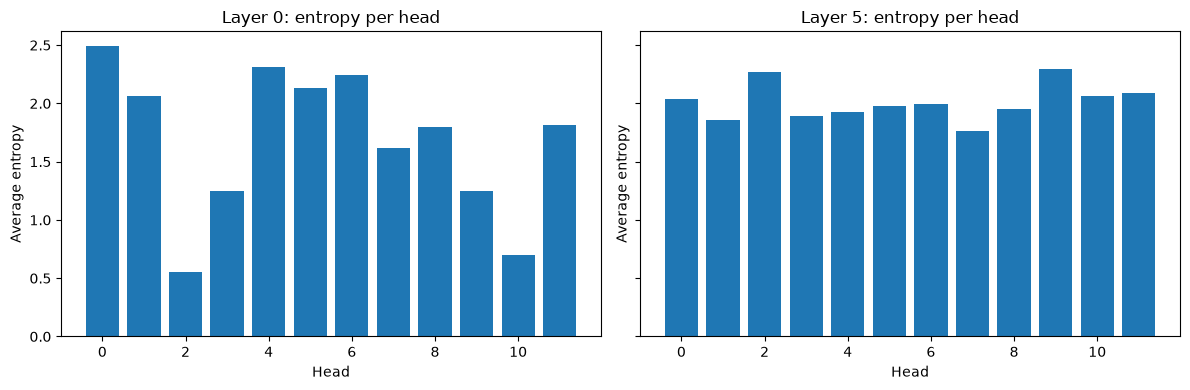

In [49]:
last_layer = len(attentions) - 1
layer_ids = [0, last_layer]
mean_entropy = []

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for i in range(len(layer_ids)):
    layer = layer_ids[i]
    att = attentions[layer][0]
    entropy = -(att * torch.log(att + 1e-12)).sum(dim=-1).mean(dim=-1)
    mean_entropy.append(entropy.mean().item())
    axes[i].bar(range(len(entropy)), entropy.numpy())
    axes[i].set_title("Layer " + str(layer) + ": entropy per head")
    axes[i].set_xlabel("Head")
    axes[i].set_ylabel("Average entropy")
plt.tight_layout()
plt.show()

In [50]:
print("Mean entropy, first layer:", round(mean_entropy[0], 3))
print("Mean entropy, last layer:", round(mean_entropy[1], 3))

Mean entropy, first layer: 1.686
Mean entropy, last layer: 2.01


**Interpretation**
- Low entropy means a focused head, high entropy means a head spread over many tokens.
- Compare the two printed numbers. This is one sentence and one sentence only: with one sentence, we cannot claim a rule for all models.

### 3.4 Sinusoidal positional encoding from scratch

In [51]:
n_positions = 50
d_pe = 128

positions = np.arange(n_positions)[:, None]
dims = np.arange(0, d_pe, 2)[None, :]
angles = positions / np.power(10000, dims / d_pe)

In [52]:
PE = np.zeros((n_positions, d_pe))
PE[:, 0::2] = np.sin(angles)
PE[:, 1::2] = np.cos(angles)
print("PE shape:", PE.shape)

PE shape: (50, 128)


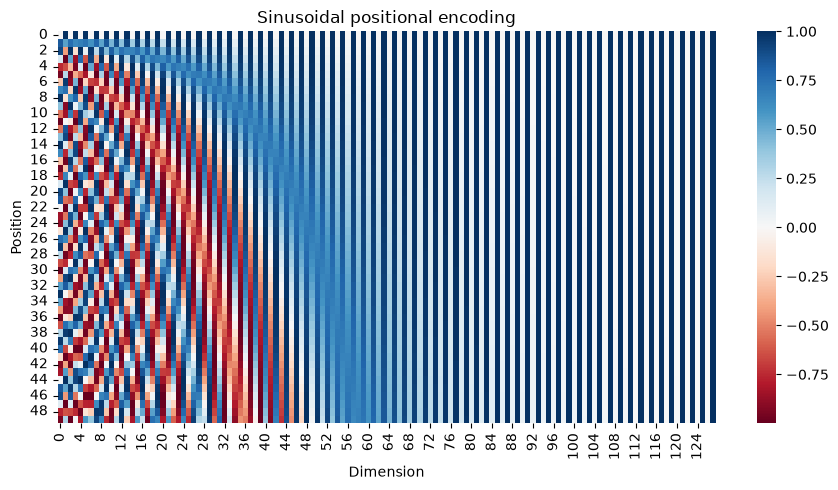

In [53]:
plt.figure(figsize=(9, 5))
sns.heatmap(PE, cmap="RdBu")
plt.title("Sinusoidal positional encoding")
plt.xlabel("Dimension")
plt.ylabel("Position")
plt.tight_layout()
plt.savefig("plots/positional_encoding.png", dpi=150)
plt.show()

**Interpretation**
- Left dimensions change fast (high frequency) and right dimensions change slowly, so every position gets a unique pattern.
- Sines and cosines make relative offsets easy to learn, because a shift in position is a simple rotation of the pattern.

### 3.5 Position makes identical words different

In [54]:
def cosine(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

In [55]:
word = rng.standard_normal(d_pe)
at_pos_3 = word + PE[3]
at_pos_20 = word + PE[20]

In [56]:
print("Cosine without PE:", round(cosine(word, word), 3))
print("Cosine with PE (position 3 vs 20):", round(cosine(at_pos_3, at_pos_20), 3))

Cosine without PE: 1.0
Cosine with PE (position 3 vs 20): 0.868


**Interpretation**
- The same word is no longer identical after adding PE, so the similarity falls below 1.
- Now the input to attention carries position, so shuffling the tokens (Task 2.5) would change the output. This removes the order-blindness.

### 3.6 Learned positional embeddings in a real model

In [57]:
pos_weights = model.distilbert.embeddings.position_embeddings.weight.detach().numpy()
print("Position embedding shape:", pos_weights.shape)

Position embedding shape: (512, 768)


In [58]:
first_64 = pos_weights[:64]
norms = np.linalg.norm(first_64, axis=1, keepdims=True)
pos_similarity = (first_64 / norms) @ (first_64 / norms).T

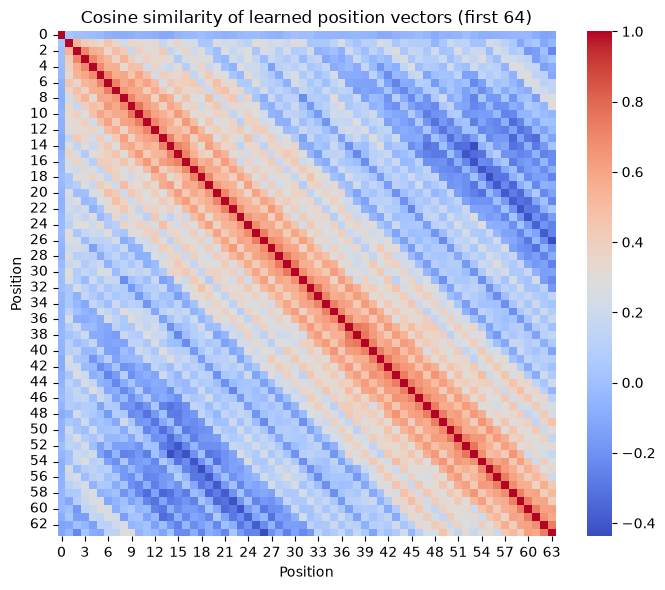

In [59]:
plt.figure(figsize=(7, 6))
sns.heatmap(pos_similarity, cmap="coolwarm")
plt.title("Cosine similarity of learned position vectors (first 64)")
plt.xlabel("Position")
plt.ylabel("Position")
plt.tight_layout()
plt.show()

**Interpretation**
- BERT-style models learn their position vectors instead of using sinusoids. Nearby positions usually look more similar.
- The table has only 512 rows, so 512 is the maximum length. This is the origin of the context-length limit.
- T5 uses relative position biases instead (seen in Task 5).

### 3.7 Layer normalization from scratch

In [60]:
M = rng.standard_normal((4, 8))
eps = 1e-5
gamma = np.ones(M.shape[1])
beta = np.zeros(M.shape[1])

In [61]:
mean = M.mean(axis=1, keepdims=True)
var = M.var(axis=1, keepdims=True)
ln_out = gamma * (M - mean) / np.sqrt(var + eps) + beta

In [62]:
print("Per-token mean:", np.round(ln_out.mean(axis=1), 4))
print("Per-token std :", np.round(ln_out.std(axis=1), 4))

Per-token mean: [0. 0. 0. 0.]
Per-token std : [1. 1. 1. 1.]


In [63]:
torch_ln = torch.nn.LayerNorm(M.shape[1], eps=eps)
torch_out = torch_ln(torch.tensor(M, dtype=torch.float32))
print("Same as torch LayerNorm:", torch.allclose(torch.tensor(ln_out, dtype=torch.float32), torch_out, atol=1e-5))

Same as torch LayerNorm: True


**Interpretation**
- Each token vector now has mean about 0 and std about 1, because the statistics are taken over the features of that single token.
- The result matches PyTorch.

### 3.8 LayerNorm vs BatchNorm

In [64]:
bn_mean = M.mean(axis=0, keepdims=True)
bn_var = M.var(axis=0, keepdims=True)
bn_out = (M - bn_mean) / np.sqrt(bn_var + eps)

In [65]:
print("BatchNorm, per-feature mean:", np.round(bn_out.mean(axis=0), 4))
print("BatchNorm, per-token mean  :", np.round(bn_out.mean(axis=1), 4))
print("BatchNorm, per-token std   :", np.round(bn_out.std(axis=1), 4))

BatchNorm, per-feature mean: [ 0. -0. -0. -0. -0.  0. -0.  0.]
BatchNorm, per-token mean  : [ 0.0934  0.4613 -0.269  -0.2856]
BatchNorm, per-token std   : [0.9765 0.9612 1.1493 0.6528]


| Point | LayerNorm | BatchNorm |
|---|---|---|
| Normalised over | Features of one token | One feature across the batch / tokens |
| Batch size dependence | None | Yes, needs a reasonable batch |
| Variable length and padding | Works, every token alone | Padding disturbs the statistics |
| Used in Transformers | Yes | No (it was used in PR 2 for fixed-size inputs) |

**Interpretation**
- BatchNorm makes each feature normal, but the per-token mean and std are not 0 and 1.
- LayerNorm does not depend on other tokens or on batch size, so it suits variable-length text.

In [66]:
ln_layer = model.distilbert.embeddings.LayerNorm
print("gamma shape:", ln_layer.weight.shape)
print("beta shape :", ln_layer.bias.shape)
print("First 5 gamma:", ln_layer.weight[:5].detach().numpy())

gamma shape: torch.Size([768])
beta shape : torch.Size([768])
First 5 gamma: [0.84453845 0.7973702  0.7331022  0.7594067  0.8013367 ]


- gamma is a learned scale and beta is a learned shift for each of the 768 features. They let the model undo the normalisation if needed.

### Final interpretation: Task 3
- Many heads give many different views of the same sentence.
- Positional encoding gives order to attention, and LayerNorm keeps each token vector stable.
- The hand-made LayerNorm matches PyTorch, so the formula is clear.

## Task 4: Transformer Encoder Architecture & Masked Self-Attention
**Objective:** Read the real encoder, count where its parameters live, and compare bidirectional and masked attention.

**Expected output:** Module table, parameter chart, fill-mask predictions, and attention heatmaps with and without a mask.

### 4.1 Encoder architecture
- Input embeddings + positional information go into N stacked blocks.
- Each block: multi-head self-attention → residual connection + layer norm → feed-forward network (expand, non-linearity, project back) → residual connection + layer norm.
- DistilBERT has 6 such blocks. "Encoder" means every token can see every other token in both directions.

### 4.2 Print and read the real encoder

In [67]:
print(model.distilbert)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

| Part | Module name in DistilBERT |
|---|---|
| Token embedding | `embeddings.word_embeddings` |
| Position embedding | `embeddings.position_embeddings` |
| Embedding LayerNorm | `embeddings.LayerNorm` |
| Attention block | `transformer.layer[i].attention` with `q_lin`, `k_lin`, `v_lin`, `out_lin` |
| Feed-forward block | `transformer.layer[i].ffn` with `lin1`, `lin2` and the activation |
| Two layer norms per block | `sa_layer_norm` (after attention) and `output_layer_norm` (after feed-forward) |

In [68]:
ffn = model.distilbert.transformer.layer[0].ffn
print("lin1:", ffn.lin1.in_features, "->", ffn.lin1.out_features)
print("lin2:", ffn.lin2.in_features, "->", ffn.lin2.out_features)

lin1: 768 -> 3072
lin2: 3072 -> 768


**Interpretation**
- The feed-forward part expands each token vector (768 to 3072) and projects it back (3072 to 768).

### 4.3 Where do the parameters live?

In [69]:
group_counts = {}
for name, p in model.named_parameters():
    if "LayerNorm" in name or "layer_norm" in name:
        group = "layer norms"
    elif "embeddings" in name:
        group = "embeddings"
    elif "attention" in name:
        group = "attention"
    elif "ffn" in name:
        group = "feed-forward"
    else:
        group = "classification head"
    group_counts[group] = group_counts.get(group, 0) + p.numel()

In [70]:
param_table = pd.DataFrame({"group": list(group_counts.keys()), "parameters": list(group_counts.values())})
param_table["share %"] = (param_table["parameters"] / param_table["parameters"].sum() * 100).round(2)
param_table

,group,parameters,share %
0,embeddings,23834112,35.60
1,layer norms,19968,0.03
2,attention,14174208,21.17
3,feed-forward,28334592,42.32
4,classification head,592130,0.88


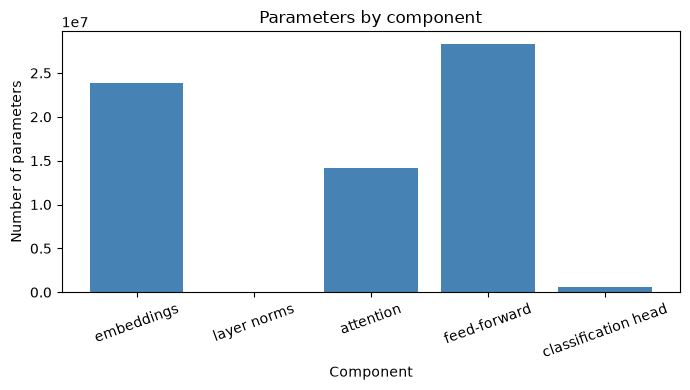

In [71]:
plt.figure(figsize=(7, 4))
plt.bar(param_table["group"], param_table["parameters"], color="steelblue")
plt.title("Parameters by component")
plt.xlabel("Component")
plt.ylabel("Number of parameters")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Interpretation**
- Check the table: the largest group holds most of the parameters.
- Embeddings (the vocabulary) and feed-forward layers are large, so a big part of what the model "knows" is stored there, not in attention.

### 4.4 Use the encoder: fill-mask

In [72]:
fill = pipeline("fill-mask", model="distilbert-base-uncased")

C:\Users\aisam\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\aisam\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 105/105 [00:00<00:00, 528.70it/s]


In [73]:
masked_sentences = [
    "The capital of France is [MASK].",
    "I would like a cup of [MASK] this morning.",
    "She opened the door and [MASK] into the room.",
]

In [74]:
for s in masked_sentences:
    print(s)
    for p in fill(s, top_k=3):
        print("   ", p["token_str"], round(p["score"], 4))

The capital of France is [MASK].
    marseille 0.1427
    nantes 0.0902
    toulouse 0.0881
I would like a cup of [MASK] this morning.
    coffee 0.6512
    tea 0.2525
    water 0.034
She opened the door and [MASK] into the room.
    stepped 0.2522
    walked 0.1702
    peered 0.0466


**Interpretation**
- The model fills the blank using words on both sides of [MASK]. This is the bidirectional encoder behaviour.

### 4.5 Bidirectional attention heatmap

In [75]:
bi_att = out.attentions[-1][0].mean(dim=0).numpy()
print("Max above diagonal:", np.triu(bi_att, k=1).max())
print("Max below diagonal:", np.tril(bi_att, k=-1).max())

Max above diagonal: 0.3990791
Max below diagonal: 0.4407413


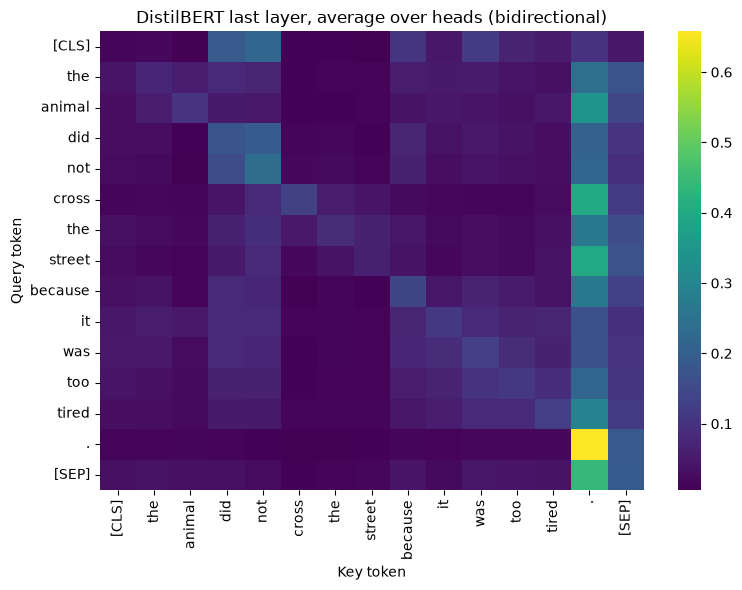

In [76]:
plt.figure(figsize=(8, 6))
sns.heatmap(bi_att, xticklabels=tokens, yticklabels=tokens, cmap="viridis")
plt.title("DistilBERT last layer, average over heads (bidirectional)")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.tight_layout()
plt.show()

**Interpretation**
- There are non-zero weights above and below the diagonal, so a token sees both left and right words.
- A language model that predicts the next word must not see future words. This leads to masked self-attention.

### 4.6 Masked (causal) self-attention from scratch

In [77]:
n_causal = 6
causal_mask = np.triu(np.full((n_causal, n_causal), -np.inf), k=1)
print(causal_mask)

[[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]


In [78]:
X_causal = rng.standard_normal((n_causal, d_model))
w_causal, out_causal = self_attention(X_causal, Wq, Wk, Wv, mask=causal_mask)

In [79]:
print("Lower triangular:", np.allclose(np.triu(w_causal, k=1), 0))
print("Rows sum to 1:", np.allclose(w_causal.sum(axis=1), 1))

Lower triangular: True
Rows sum to 1: True


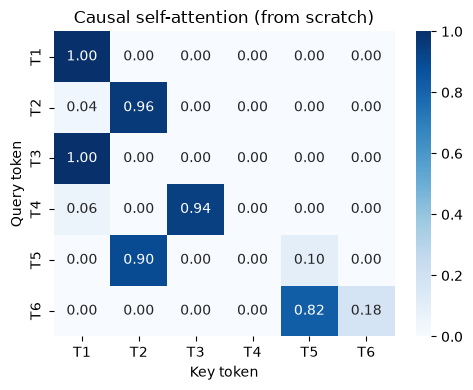

In [80]:
causal_labels = []
for i in range(n_causal):
    causal_labels.append("T" + str(i + 1))

plt.figure(figsize=(5, 4))
sns.heatmap(w_causal, annot=True, fmt=".2f", cmap="Blues", xticklabels=causal_labels, yticklabels=causal_labels)
plt.title("Causal self-attention (from scratch)")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.tight_layout()
plt.savefig("plots/causal_mask.png", dpi=150)
plt.show()

**Interpretation**
- Each token attends only to itself and earlier tokens.
- The mask (-infinity) is added before softmax, so exp(-inf) = 0 and the remaining weights still sum to 1. Zeroing weights after softmax would leave rows that do not sum to 1.

### 4.7 Causal mask in a real decoder

In [81]:
gpt_tok = AutoTokenizer.from_pretrained("gpt2")

C:\Users\aisam\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\aisam\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [82]:
from transformers import AutoModelForCausalLM

gpt = AutoModelForCausalLM.from_pretrained("gpt2", attn_implementation="eager")
gpt.eval()

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 235.57it/s]


GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [83]:
gpt_inputs = gpt_tok(sentence, return_tensors="pt")
with torch.no_grad():
    gpt_out = gpt(**gpt_inputs, output_attentions=True)

In [84]:
gpt_att = gpt_out.attentions[-1][0, 0].numpy()
gpt_tokens = gpt_tok.convert_ids_to_tokens(gpt_inputs["input_ids"][0])
print("Above diagonal is almost zero:", np.triu(gpt_att, k=1).max() < 1e-6)

Above diagonal is almost zero: True


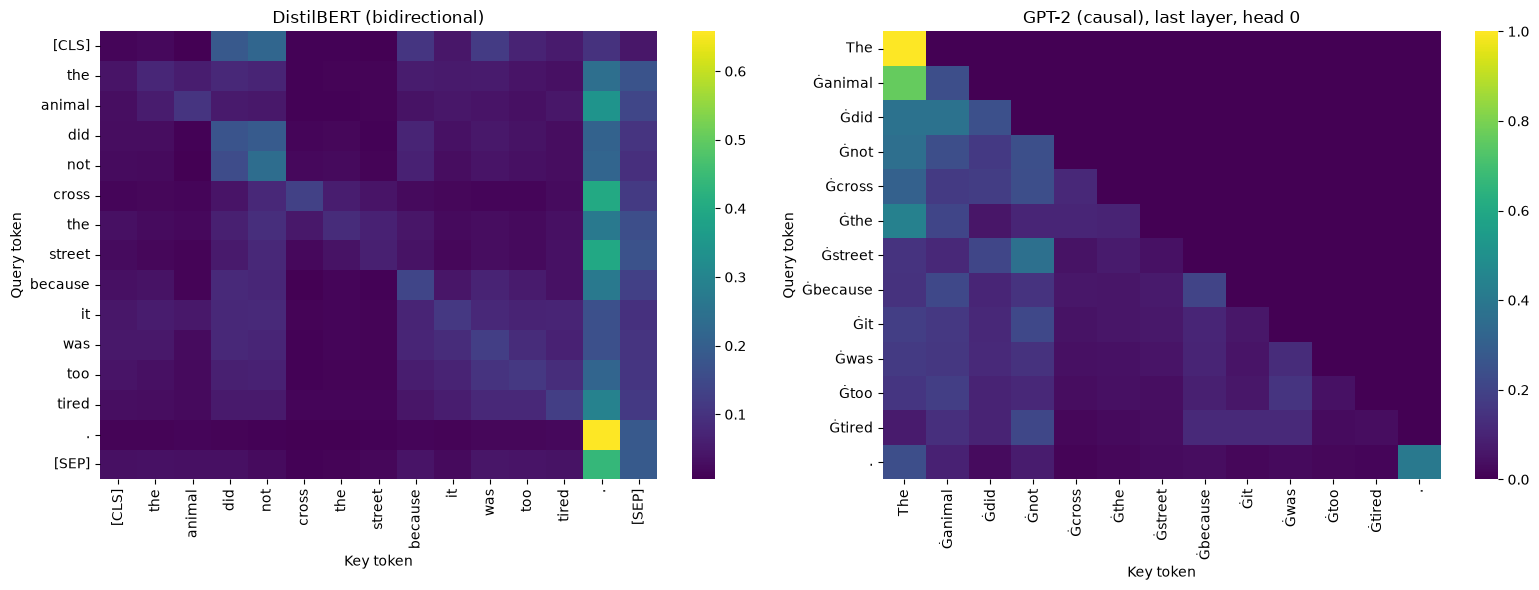

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(bi_att, xticklabels=tokens, yticklabels=tokens, cmap="viridis", ax=axes[0])
axes[0].set_title("DistilBERT (bidirectional)")
sns.heatmap(gpt_att, xticklabels=gpt_tokens, yticklabels=gpt_tokens, cmap="viridis", ax=axes[1])
axes[1].set_title("GPT-2 (causal), last layer, head 0")
for ax in axes:
    ax.set_xlabel("Key token")
    ax.set_ylabel("Query token")
plt.tight_layout()
plt.show()

**Interpretation**
- GPT-2 has a clean lower-triangular picture, while DistilBERT is filled on both sides of the diagonal.
- The numeric check confirms the future tokens get (almost) no attention.

### 4.8 Padding mask vs causal mask

In [86]:
pad_batch = tok(two_sentences, padding=True, return_tensors="pt")
with torch.no_grad():
    pad_out = base(**pad_batch, output_attentions=True)

In [87]:
short_row = pad_batch["attention_mask"].sum(dim=1).argmin().item()
pad_positions = torch.where(pad_batch["attention_mask"][short_row] == 0)[0]
print("Short sentence is row", short_row, "with padding at positions", pad_positions.tolist())

Short sentence is row 0 with padding at positions [6, 7, 8, 9, 10, 11, 12, 13]


In [88]:
largest = 0
for layer_att in pad_out.attentions:
    to_pad = layer_att[short_row][:, :, pad_positions]
    largest = max(largest, to_pad.max().item())
print("Largest attention received by a padding position (all layers):", largest)

Largest attention received by a padding position (all layers): 0


| Point | Padding mask | Causal mask |
|---|---|---|
| Purpose | Ignore padding tokens | Hide future tokens |
| Shape pattern | Blocks the padded columns | Blocks above the diagonal |
| Model families | Encoder and decoder (any batch with padding) | Decoder-only and decoder side of encoder-decoder |

**Interpretation**
- The attention received by padding is (almost) zero, so padding does not change the result for real tokens.

### Final interpretation: Task 4
- The encoder is a stack of attention + feed-forward blocks with residual connections and layer norms.
- Encoders see both sides of a token, decoders are blocked from the future by a causal mask.
- The mask built by hand behaves the same as the mask inside GPT-2.

## Task 5: Cross-Attention, Decoder Architecture & Inference
**Objective:** Use an encoder-decoder model, look at cross-attention, and see how text is generated token by token.

**Expected output:** Translation and summary, cross-attention heatmap, manual decoding loop, decoding strategies table and KV-cache timing.

### 5.1 Decoder architecture
- Original decoder block: masked multi-head self-attention → add and norm → cross-attention over the encoder output → add and norm → feed-forward → add and norm. After the blocks come a linear layer and softmax over the vocabulary.
- Encoder-only (DistilBERT, BERT): understanding tasks.
- Decoder-only (GPT-2): drops cross-attention, generates text.
- Encoder-decoder (T5): keeps both, used for translation and summaries.

### 5.2 Cross-attention
- In cross-attention the Queries come from the decoder, while the Keys and Values come from the encoder output.
- This lets the decoder look at the source sentence while it writes the target sentence.
- It is the same idea as Luong attention in Task 2.4, but inside a Transformer and with many heads.

### 5.3 Run an encoder-decoder model

In [91]:
from transformers import T5ForConditionalGeneration

In [92]:
t5_tok = AutoTokenizer.from_pretrained("t5-small")

In [93]:
t5 = T5ForConditionalGeneration.from_pretrained("t5-small", attn_implementation="eager")
t5.eval()

Loading weights: 100%|██████████| 131/131 [00:00<00:00, 1132.83it/s]


T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=512, bias=False)
              (k): Linear(in_features=512, out_features=512, bias=False)
              (v): Linear(in_features=512, out_features=512, bias=False)
              (o): Linear(in_features=512, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 8)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseActDense(
              (wi): Linear(in_features=512, out_features=2048, bias=False)
              (wo): Linear(in_features=2048, out_features=512, bias=False)
              (dropout): Drop

In [97]:
def t5_run(task_text, max_length=60, min_length=0):
    input_ids = t5_tok(task_text, return_tensors="pt", truncation=True, max_length=512).input_ids
    with torch.no_grad():
        output_ids = t5.generate(input_ids, max_length=max_length, min_length=min_length, num_beams=4, early_stopping=True)
    return t5_tok.decode(output_ids[0], skip_special_tokens=True)

In [98]:
english = [
    "The weather is very nice today.",
    "I would like to buy a ticket for the evening train.",
    "Learning how Transformers work is exciting.",
]

In [99]:
for e in english:
    french = t5_run("translate English to French : " + e)
    print(e, "--> ", french)

The weather is very nice today. -->  Le temps est très agréable aujourd'hui.
I would like to buy a ticket for the evening train. -->  Je voudrais acheter un billet pour le train de soirée.
Learning how Transformers work is exciting. -->  L'apprentissage de la façon dont les transformateurs fonctionnent est passionnant.


In [103]:
article = """Public libraries in many cities are changing the way they serve their visitors. Besides lending books, they now offer free internet access, computer classes and quiet rooms where students can prepare for exams. Many libraries have also started digital lending, so that readers can borrow e-books and audiobooks on their phones without visiting the building. Library staff say that the number of visitors to workshops has grown steadily, especially among older adults who want to learn how to use smartphones and online banking safely. Some branches now stay open late in the evening to support people who work during the day. To pay for these services, city councils have combined small public budgets with donations from local businesses and volunteers. Supporters argue that libraries remain one of the few public places where anyone can learn without paying a fee, while critics worry that rising costs may force some small branches to reduce their opening hours in the coming years."""

In [104]:
summary = t5_run("summarize: " + article, max_length=60, min_length=20)
print(summary)
print("Input words  :", len(article.split()))
print("Summary words:", len(summary.split()))

libraries in many cities are changing the way they serve their visitors. they offer free internet access, computer classes and quiet rooms. some branches stay open late in the evening to support people who work during the day.
Input words  : 159
Summary words: 38


**Interpretation**
- T5 is one model that does translation and summarisation, only the task text changes.
- The summary is much shorter than the input, and it mostly reuses sentences or phrases from the paragraph.

### 5.4 Extract and plot cross-attention

In [106]:
from transformers import T5ForConditionalGeneration

t5_tok = AutoTokenizer.from_pretrained("t5-small")
t5 = T5ForConditionalGeneration.from_pretrained("t5-small", attn_implementation="eager")
t5.eval()

Loading weights: 100%|██████████| 131/131 [00:00<00:00, 1213.48it/s]


T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=512, bias=False)
              (k): Linear(in_features=512, out_features=512, bias=False)
              (v): Linear(in_features=512, out_features=512, bias=False)
              (o): Linear(in_features=512, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 8)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseActDense(
              (wi): Linear(in_features=512, out_features=2048, bias=False)
              (wo): Linear(in_features=2048, out_features=512, bias=False)
              (dropout): Drop

In [107]:
source_text = "translate English to French: The house is small."
target_text = "La maison est petite."

src_ids = t5_tok(source_text, return_tensors="pt").input_ids
labels = t5_tok(target_text, return_tensors="pt").input_ids

In [108]:
with torch.no_grad():
    t5_out = t5(input_ids=src_ids, labels=labels, output_attentions=True)
print("Decoder layers with cross-attention:", len(t5_out.cross_attentions))
print("Last layer shape:", t5_out.cross_attentions[-1].shape)

Decoder layers with cross-attention: 6
Last layer shape: torch.Size([1, 8, 6, 11])


In [109]:
cross = t5_out.cross_attentions[-1][0].mean(dim=0).numpy()
src_tokens = t5_tok.convert_ids_to_tokens(src_ids[0])
tgt_tokens = t5_tok.convert_ids_to_tokens(labels[0])

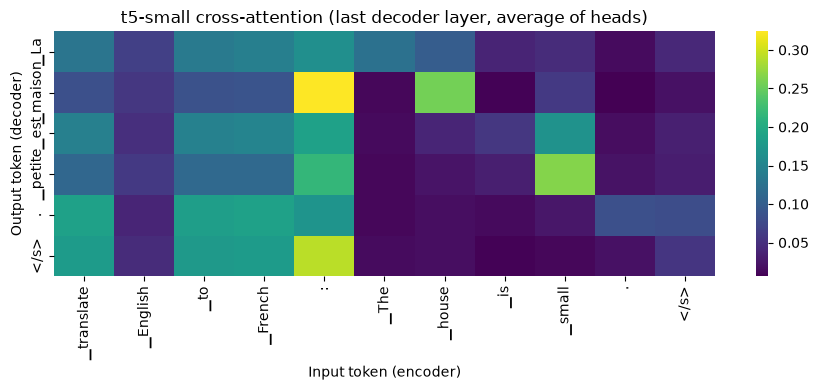

In [110]:
plt.figure(figsize=(9, 4))
sns.heatmap(cross, xticklabels=src_tokens, yticklabels=tgt_tokens, cmap="viridis")
plt.title("t5-small cross-attention (last decoder layer, average of heads)")
plt.xlabel("Input token (encoder)")
plt.ylabel("Output token (decoder)")
plt.tight_layout()
plt.savefig("plots/cross_attention.png", dpi=150)
plt.show()

In [111]:
for i in range(len(tgt_tokens)):
    print(tgt_tokens[i], "->", src_tokens[cross[i].argmax()])

▁La -> :
▁maison -> :
▁est -> :
▁petite -> ▁small
. -> ▁French
</s> -> :


**Interpretation**
- Rows are output tokens and columns are input tokens. The list above shows the input token each output token looks at most.
- Check if "maison" looks at "house" and "petite" looks at "small". If yes, the alignment is sensible. If not, one layer and the average of heads is only a rough view.

### 5.5 Inference is autoregressive: manual loop

In [112]:
prompt = "Artificial intelligence will"
prompt_ids = gpt_tok(prompt, return_tensors="pt").input_ids
new_tokens = 20

In [113]:
manual_ids = prompt_ids.clone()
for step in range(new_tokens):
    with torch.no_grad():
        logits = gpt(manual_ids).logits
    next_id = logits[:, -1, :].argmax(dim=-1, keepdim=True)
    manual_ids = torch.cat([manual_ids, next_id], dim=1)

print(gpt_tok.decode(manual_ids[0]))

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who


In [114]:
generated_ids = gpt.generate(prompt_ids, max_new_tokens=new_tokens, do_sample=False, pad_token_id=gpt_tok.eos_token_id)
print(gpt_tok.decode(generated_ids[0]))
print("Identical:", torch.equal(manual_ids, generated_ids))

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
Identical: True


**Interpretation**
- A decoder produces ONE token at a time and feeds it back as input for the next step.
- Our own loop gives the same text as `generate()`, so `generate()` is just this loop with extras.

### 5.6 Decoding strategies

In [115]:
long_tokens = 40
pad_id = gpt_tok.eos_token_id

In [116]:
greedy_ids = gpt.generate(prompt_ids, max_new_tokens=long_tokens, do_sample=False, pad_token_id=pad_id)
greedy_text = gpt_tok.decode(greedy_ids[0], skip_special_tokens=True)
print(greedy_text)

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's in the right place at the right time.

"We're going to be able to


In [117]:
beam_ids = gpt.generate(prompt_ids, max_new_tokens=long_tokens, num_beams=5, early_stopping=True, do_sample=False, pad_token_id=pad_id)
beam_text = gpt_tok.decode(beam_ids[0], skip_special_tokens=True)
print(beam_text)

Artificial intelligence will be the next big thing, and it's going to take a lot of work to get there.

"I think it's going to take a lot of work to get there," he said


In [118]:
torch.manual_seed(1)
t07_a = gpt.generate(prompt_ids, max_new_tokens=long_tokens, do_sample=True, temperature=0.7, top_k=0, pad_token_id=pad_id)
torch.manual_seed(2)
t07_b = gpt.generate(prompt_ids, max_new_tokens=long_tokens, do_sample=True, temperature=0.7, top_k=0, pad_token_id=pad_id)
t07_a_text = gpt_tok.decode(t07_a[0], skip_special_tokens=True)
t07_b_text = gpt_tok.decode(t07_b[0], skip_special_tokens=True)
print(t07_a_text)
print(t07_b_text)

Artificial intelligence will help us shape the future of the world.

I am really excited about the future of AI. It is already possible to solve problems of intelligence, computation, and communication and it is also possible
Artificial intelligence will not be able to solve problems that have never been solved.

The researchers note that the story of the self-driving car is like a tale of two halves: one is a self-driving


In [119]:
torch.manual_seed(1)
t15_a = gpt.generate(prompt_ids, max_new_tokens=long_tokens, do_sample=True, temperature=1.5, top_k=0, pad_token_id=pad_id)
torch.manual_seed(2)
t15_b = gpt.generate(prompt_ids, max_new_tokens=long_tokens, do_sample=True, temperature=1.5, top_k=0, pad_token_id=pad_id)
t15_a_text = gpt_tok.decode(t15_a[0], skip_special_tokens=True)
t15_b_text = gpt_tok.decode(t15_b[0], skip_special_tokens=True)
print(t15_a_text)
print(t15_b_text)

Artificial intelligence will upset inertia in difficult news ones. Countries humans would respect assimil c about every trial, scaven- Detection organizations from the above won % of dislressed orally Fastaturation rofter going judge sentenced k move Tid
Artificial intelligence will not similarly distress down that angry increase paradigm and presume elsear characterShell pervasive strandsUpon childinitiality gradient spweet votingIn acid GUI libraries pigples are choosing SpecificesKennlaus communities values inputnow


In [120]:
torch.manual_seed(1)
topk_ids = gpt.generate(prompt_ids, max_new_tokens=long_tokens, do_sample=True, top_k=50, top_p=0.9, pad_token_id=pad_id)
topk_text = gpt_tok.decode(topk_ids[0], skip_special_tokens=True)
print(topk_text)

Artificial intelligence will help with our search, and perhaps even help us decide which products to buy and which ones not to buy at the moment. I suspect this technology will have its future in the form of advertising, or


In [121]:
pd.set_option("display.max_colwidth", None)
decoding_table = pd.DataFrame({
    "Strategy": ["Greedy", "Beam (5)", "Temp 0.7 (seed 1)", "Temp 0.7 (seed 2)", "Temp 1.5 (seed 1)", "Temp 1.5 (seed 2)", "Top-k 50 + top-p 0.9"],
    "Output": [greedy_text, beam_text, t07_a_text, t07_b_text, t15_a_text, t15_b_text, topk_text],
})
decoding_table

,Strategy,Output
0,Greedy,"Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's in the right place at the right time.\n\n""We're going to be able to"
1,Beam (5),"Artificial intelligence will be the next big thing, and it's going to take a lot of work to get there.\n\n""I think it's going to take a lot of work to get there,"" he said"
2,Temp 0.7 (seed 1),"Artificial intelligence will help us shape the future of the world.\n\nI am really excited about the future of AI. It is already possible to solve problems of intelligence, computation, and communication and it is also possible"
3,Temp 0.7 (seed 2),Artificial intelligence will not be able to solve problems that have never been solved.\n\nThe researchers note that the story of the self-driving car is like a tale of two halves: one is a self-driving
4,Temp 1.5 (seed 1),"Artificial intelligence will upset inertia in difficult news ones. Countries humans would respect assimil c about every trial, scaven- Detection organizations from the above won % of dislressed orally Fastaturation rofter going judge sentenced k move Tid"
5,Temp 1.5 (seed 2),Artificial intelligence will not similarly distress down that angry increase paradigm and presume elsear characterShell pervasive strandsUpon childinitiality gradient spweet votingIn acid GUI libraries pigples are choosing SpecificesKennlaus communities values inputnow
6,Top-k 50 + top-p 0.9,"Artificial intelligence will help with our search, and perhaps even help us decide which products to buy and which ones not to buy at the moment. I suspect this technology will have its future in the form of advertising, or"


**Interpretation**
- Greedy and beam search are deterministic: same prompt, same text. They can repeat phrases.
- Low temperature (0.7) makes sampling safer, high temperature (1.5) makes it more random and less sensible. Different seeds give different texts.
- Top-k and top-p cut away very unlikely tokens, so sampling stays random but avoids nonsense words.

### 5.7 KV-cache speed-up

In [122]:
import time

def average_time(use_cache):
    times = []
    for i in range(3):
        start = time.time()
        gpt.generate(prompt_ids, max_new_tokens=100, min_new_tokens=100, do_sample=False, use_cache=use_cache, pad_token_id=pad_id)
        times.append(time.time() - start)
    return sum(times) / len(times)

In [123]:
time_with_cache = average_time(True)
time_without_cache = average_time(False)
print("With cache   :", round(time_with_cache, 2), "seconds")
print("Without cache:", round(time_without_cache, 2), "seconds")
print("Speed-up     :", round(time_without_cache / time_with_cache, 2), "x")

With cache   : 1.93 seconds
Without cache: 4.3 seconds
Speed-up     : 2.23 x


**Interpretation**
- Key and value vectors of earlier tokens do not change, so they can be stored (cached) instead of computed again at every step.
- This is the main speed trick in Transformer inference. The speed-up above is the proof on this machine.

### 5.8 Inference summary table
| Model | Family | Attention type(s) | Can generate text | Position scheme | Typical tasks | Example in this notebook |
|---|---|---|---|---|---|---|
| DistilBERT | Encoder-only | Bidirectional self-attention | No (not by itself) | Learned | Classification, fill-mask | Sentiment, fill-mask |
| GPT-2 | Decoder-only | Masked (causal) self-attention | Yes | Learned | Text generation | Greedy loop, decoding strategies |
| T5-small | Encoder-decoder | Self-attention + masked self-attention + cross-attention | Yes | Relative position bias | Translation, summarisation | EN to FR, summary |

### Final interpretation: Task 5
- Cross-attention connects the target sentence to the source sentence.
- Generation is a loop: predict one token, append it, repeat.
- Decoding settings change the text, and the KV-cache makes the loop faster.

## Task 6: Mini Application, Evaluation & Disadvantages in Practice
**Objective:** Evaluate the pretrained sentiment model, measure two disadvantages, and build a small text toolkit.

**Expected output:** Metrics, truncation study, time-vs-length plot, hallucination check, `text_toolkit()` table, reflection.

### 6.1 Evaluate the pretrained sentiment model

In [127]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb", split="test").shuffle(seed=42).select(range(200))
texts = list(ds["text"])
true_labels = np.array(ds["label"])
print("Reviews:", len(texts), "| Positive:", int(true_labels.sum()))

C:\Users\aisam\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\aisam\.cache\huggingface\hub\datasets--stanfordnlp--imdb. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Generating unsupervised split: 100%|██████████| 50000/50000 [00:00<00:00, 665663.22 examples/s]

Reviews: 200 | Positive: 96


In [128]:
review_outputs = clf(texts, truncation=True, max_length=512, batch_size=16)

In [129]:
predictions = []
for o in review_outputs:
    if o["label"] == "POSITIVE":
        predictions.append(1)
    else:
        predictions.append(0)
predictions = np.array(predictions)

In [130]:
tp = np.sum((predictions == 1) & (true_labels == 1))
tn = np.sum((predictions == 0) & (true_labels == 0))
fp = np.sum((predictions == 1) & (true_labels == 0))
fn = np.sum((predictions == 0) & (true_labels == 1))

accuracy = (tp + tn) / len(true_labels)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 score :", round(f1, 4))

Accuracy : 0.87
Precision: 0.8889
Recall   : 0.8333
F1 score : 0.8602


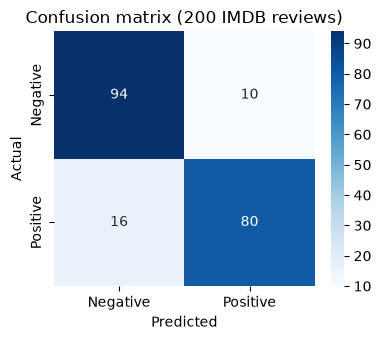

In [131]:
conf = np.array([[tn, fp], [fn, tp]])
plt.figure(figsize=(4, 3.5))
sns.heatmap(conf, annot=True, fmt="d", cmap="Blues", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.title("Confusion matrix (200 IMDB reviews)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

**Interpretation**
- Nothing was trained here. The model was fine-tuned earlier on a different dataset (SST-2, short sentences) and is tested on IMDB.
- The confusion matrix shows which class the model confuses more often. Long reviews are cut at 512 tokens.

### 6.2 Effect of truncation length

In [132]:
def run_eval(max_len):
    start = time.time()
    outs = clf(texts, truncation=True, max_length=max_len, batch_size=16)
    seconds = time.time() - start
    preds = []
    for o in outs:
        if o["label"] == "POSITIVE":
            preds.append(1)
        else:
            preds.append(0)
    return np.mean(np.array(preds) == true_labels), seconds

In [133]:
max_lengths = [64, 128, 256, 512]
accuracies = []
run_times = []
for m in max_lengths:
    acc, sec = run_eval(m)
    accuracies.append(acc)
    run_times.append(sec)
    print("max_length", m, "| accuracy", round(acc, 4), "| time", round(sec, 1), "s")

max_length 64 | accuracy 0.75 | time 0.5 s
max_length 128 | accuracy 0.775 | time 0.7 s
max_length 256 | accuracy 0.84 | time 1.2 s
max_length 512 | accuracy 0.87 | time 2.5 s


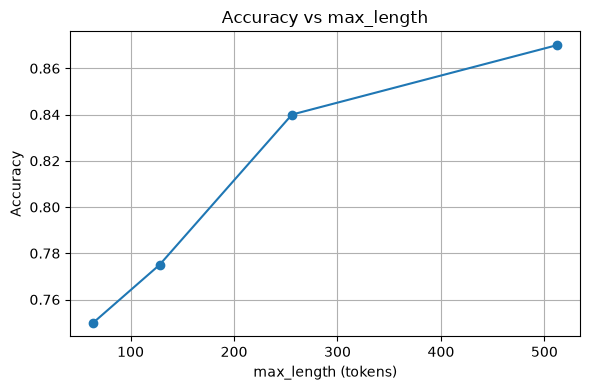

In [134]:
plt.figure(figsize=(6, 4))
plt.plot(max_lengths, accuracies, marker="o")
plt.title("Accuracy vs max_length")
plt.xlabel("max_length (tokens)")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/truncation_accuracy.png", dpi=150)
plt.show()

In [135]:
token_ids = tok(texts)["input_ids"]
review_lengths = []
for ids in token_ids:
    review_lengths.append(len(ids))
review_lengths = np.array(review_lengths)

over_limit = int((review_lengths > 512).sum())
print("Reviews longer than 512 tokens:", over_limit, "out of", len(texts))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


Reviews longer than 512 tokens: 18 out of 200


In [136]:
print("Accuracy lost between 512 and 64 tokens:", round(accuracies[-1] - accuracies[0], 4))
print("Time at 64 tokens:", round(run_times[0], 1), "s | time at 512 tokens:", round(run_times[-1], 1), "s")

Accuracy lost between 512 and 64 tokens: 0.12
Time at 64 tokens: 0.5 s | time at 512 tokens: 2.5 s


**Interpretation**
- A smaller context window means less text is read. The printed difference shows how much accuracy is lost.
- A bigger window costs more time. This is the fixed context window disadvantage, and the reviews above 512 tokens lose text even at the maximum setting.

### 6.3 Cost grows with sequence length

In [137]:
long_text = " ".join(texts[:10])
all_ids = tok(long_text)["input_ids"]
print("Available tokens:", len(all_ids))

Available tokens: 1931


In [138]:
lengths = [32, 64, 128, 256, 512]

def forward_time(length):
    input_ids = torch.tensor([all_ids[:length]])
    with torch.no_grad():
        model(input_ids=input_ids)
        times = []
        for i in range(10):
            start = time.perf_counter()
            model(input_ids=input_ids)
            times.append(time.perf_counter() - start)
    return sum(times) / len(times)

In [139]:
forward_times = []
for L in lengths:
    t = forward_time(L)
    forward_times.append(t)
    print("length", L, "| time", round(t * 1000, 1), "ms")

length 32 | time 12.4 ms
length 64 | time 19.9 ms
length 128 | time 39.2 ms
length 256 | time 67.0 ms
length 512 | time 121.4 ms


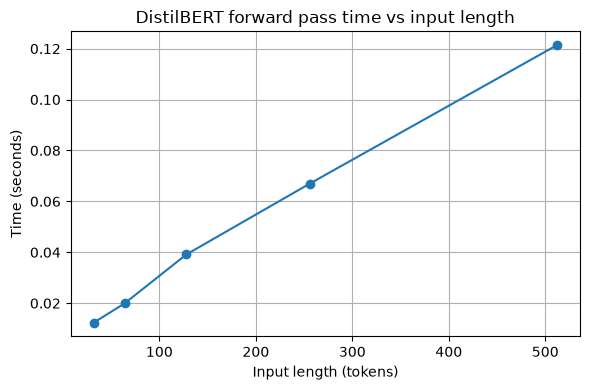

In [140]:
plt.figure(figsize=(6, 4))
plt.plot(lengths, forward_times, marker="o")
plt.title("DistilBERT forward pass time vs input length")
plt.xlabel("Input length (tokens)")
plt.ylabel("Time (seconds)")
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/time_vs_length.png", dpi=150)
plt.show()

In [141]:
length_ratio = lengths[-1] / lengths[0]
time_ratio = forward_times[-1] / forward_times[0]
print("Length grew", length_ratio, "x")
print("Time grew", round(time_ratio, 1), "x")
print("Linear growth would be", length_ratio, "x and quadratic growth would be", length_ratio ** 2, "x")

Length grew 16.0 x
Time grew 9.8 x
Linear growth would be 16.0 x and quadratic growth would be 256.0 x


**Interpretation**
- Attention compares every token with every other token, so its cost grows roughly with the square of the length. This is why the context window is limited to 512.
- Compare the three numbers above. On a CPU at small sizes the other layers (feed-forward) and fixed overhead dominate, so the curve can look closer to linear than quadratic.

### 6.4 Hallucination check

In [142]:
fact_prompts = [
    "The capital of Australia is",
    "The author of the novel Pride and Prejudice is",
    "The inventor of the telephone was",
]
expected_words = ["Canberra", "Austen", "Bell"]

In [143]:
fact_outputs = []
for p in fact_prompts:
    p_ids = gpt_tok(p, return_tensors="pt").input_ids
    gen = gpt.generate(p_ids, max_new_tokens=30, do_sample=False, pad_token_id=pad_id)
    fact_outputs.append(gpt_tok.decode(gen[0], skip_special_tokens=True))

In [144]:
grades = []
for i in range(len(fact_prompts)):
    if expected_words[i] in fact_outputs[i]:
        grades.append("correct (check the rest of the text)")
    else:
        grades.append("wrong")

fact_table = pd.DataFrame({"Prompt": fact_prompts, "Output": fact_outputs, "Grade": grades})
fact_table

,Prompt,Output,Grade
0,The capital of Australia is,"The capital of Australia is the world's largest producer of coal, and the country's largest coal-fired power station.\n\nThe coal industry is also the world's largest",wrong
1,The author of the novel Pride and Prejudice is,The author of the novel Pride and Prejudice is a former member of the National Security Council.\n\nThe author of the novel is a former member of the National Security Council.\n\nThe author,wrong
2,The inventor of the telephone was,The inventor of the telephone was a man named John D. Rockefeller. He was a man who had been a member of the Rockefeller family for many years. He was a man who,wrong


**Interpretation**
- The grade is a simple keyword check. Read each output yourself and change a grade to "partly correct" if the answer is right but the extra text is made up.
- GPT-2 predicts likely next words, not true facts. It writes fluent text even when the fact is wrong, which is hallucination. Generative models are not a safe source of facts.

### 6.5 Build the mini application

In [145]:
word_limit = 300

In [149]:
def text_toolkit(text):
    result = {"sentiment": "", "score": 0.0, "summary": "", "french summary": "", "note": ""}

    if text is None or text.strip() == "":
        result["note"] = "Empty input, nothing to process."
        return result

    words = text.split()
    if len(words) > word_limit:
        text = " ".join(words[:word_limit])
        result["note"] = "Long input, only the first " + str(word_limit) + " words were used."

    sentiment = clf(text, truncation=True, max_length=512)[0]
    result["sentiment"] = sentiment["label"]
    result["score"] = round(sentiment["score"], 4)

    if len(text.split()) < 30:
        result["summary"] = text
        result["note"] = result["note"] + " Text is too short to summarise, original text used."
    else:
        result["summary"] = t5_run("summarize: " + text, max_length=60, min_length=20)

    result["french summary"] = t5_run("translate English to French: " + result["summary"])
    return result

In [150]:
passage_review = "I watched this film last weekend with my family. The first half was slow, but the second half was full of surprises and the acting of the lead actor was excellent. The music matched every scene and the ending made us talk for hours. I would happily watch it again and I recommend it to anyone who enjoys a good story."
passage_news = "The city council announced a new plan to add cycle lanes on the main roads near the railway station. Officials said the work will start next month and will be finished in about six months. Shop owners have asked for more parking spaces nearby, and the council promised to hold a public meeting so residents can share their opinions before the final design is approved."
passage_own = "Our college started a weekly coding club where students solve small problems together. At first only a few students joined, but now the room is full every Friday. The seniors help the beginners, and everyone learns how to explain their code in simple words, which is a skill that is very useful in interviews and in team projects."

In [151]:
passages = [passage_review, passage_news, passage_own]
names = ["Movie review", "News paragraph", "Own passage"]

toolkit_rows = []
for i in range(len(passages)):
    r = text_toolkit(passages[i])
    r["input"] = names[i]
    toolkit_rows.append(r)

pd.DataFrame(toolkit_rows)[["input", "sentiment", "score", "summary", "french summary", "note"]]

,input,sentiment,score,summary,french summary,note
0,Movie review,POSITIVE,0.9998,"the first half was slow, but the second half was full of surprises. the acting of the lead actor was excellent.","La première moitié a été lente, mais la seconde a été remplie de surprises.",
1,News paragraph,NEGATIVE,0.9861,the work will start next month and will be finished in about six months. shop owners have asked for more parking spaces nearby.,Les propriétaires d'ateliers ont demandé d'ajouter plus d'espaces de stationnement à proximité.,
2,Own passage,POSITIVE,0.9995,our college started a weekly coding club where students solve small problems together. the seniors help the beginners and everyone learns how to explain their code in simple words.,"Notre collège a créé un club de codage hebdomadaire où les étudiants résident ensemble de petits problèmes, les aînés aident les débutants et tous apprennent à expliquer leur code en simples",


In [153]:
print("Empty input :", text_toolkit("")["note"])
very_long = passage_news * 60
print("Very long input:", text_toolkit(very_long)["note"])

Empty input : Empty input, nothing to process.
Very long input: Long input, only the first 300 words were used.


**Interpretation**
- One function combines three models: DistilBERT (encoder) for sentiment, and t5-small (encoder-decoder) for summary and translation.
- Empty text gives a clear message, and very long text is cut to a safe size instead of crashing.

### 6.6 What I learned about Transformers
**Measured disadvantages in this notebook**

In [154]:
print("1. Context window / cost: accuracy changed from", round(accuracies[0], 3), "(64 tokens) to", round(accuracies[-1], 3), "(512 tokens);",
      over_limit, "of 200 reviews are longer than 512 tokens.")
print("   Forward-pass time grew", round(time_ratio, 1), "x when the length grew", length_ratio, "x.")
print("2. Hallucination: GPT-2 factual prompts graded as:", grades)

1. Context window / cost: accuracy changed from 0.75 (64 tokens) to 0.87 (512 tokens); 18 of 200 reviews are longer than 512 tokens.
   Forward-pass time grew 9.8 x when the length grew 16.0 x.
2. Hallucination: GPT-2 factual prompts graded as: ['wrong', 'wrong', 'wrong']


**Draft reflection (edit in your own words)**
- **(a) Understood best / still unclear:** Self-attention (Q, K, V and softmax) is the clearest part because it was built by hand. Multi-head attention is less clear, because the heads are hard to explain one by one.
- **(b) Matched theory / surprise:** The hand-made attention matched DistilBERT, and the causal mask in GPT-2 was zero above the diagonal, as in theory. The surprise is how much of the parameters sit in embeddings and feed-forward layers, not in attention.
- **(c) Disadvantages observed:** The fixed context window with its time cost, and hallucination in GPT-2 (numbers above).
- **(d) Application I would build:** A review analysis tool that gives sentiment and a short summary. It needs an encoder model for sentiment and an encoder-decoder model for summarising.

## Final interpretation
- A Transformer is built from simple parts: Q, K, V attention, multiple heads, position information, layer norm and feed-forward layers.
- Encoder models read both sides, decoder models are masked and generate one token at a time, and encoder-decoder models connect the two with cross-attention.
- The same ideas explain the limits seen in practice: a fixed context window, growing cost with length, and made-up facts.